In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")
print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os
from google.colab import files

dataset_path = "/content/heart.csv"

if not os.path.exists(dataset_path):
    print("Please select your heart.csv dataset.")
    uploaded = files.upload()

    csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

    if not csv_files:
        raise FileNotFoundError("No CSV file was uploaded.")

    dataset_path = csv_files[0]

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1025, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nTarget column candidates:")
print([
    col for col in df.columns
    if col.strip().lower() in
    ["target", "heartdisease", "heart_disease", "output", "num"]
])

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing values:


,Missing Values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0



Duplicate rows: 723

Statistical summary:


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2



Target column candidates:
['target']


In [4]:
target_candidates = ["target", "heartdisease", "heart_disease", "output", "num"]

matched_targets = [
    col for col in df.columns
    if col.strip().lower() in target_candidates
]

if not matched_targets:
    raise ValueError(
        "Target column not detected automatically. "
        "Check the column names printed in Cell 3 and set TARGET_COLUMN manually."
    )

TARGET_COLUMN = matched_targets[0]

print("Selected target column:", TARGET_COLUMN)

# Remove duplicate rows and rows without a target
data = df.drop_duplicates().copy()
data = data.dropna(subset=[TARGET_COLUMN])

X = data.drop(columns=[TARGET_COLUMN])
y = data[TARGET_COLUMN]

# Convert categorical input columns to numerical columns
X = pd.get_dummies(X, drop_first=False)

# Fill missing feature values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().sort_index().to_frame("Count"))

print("\nPrepared features:")
display(X.head())

Selected target column: target
Features shape: (302, 13)
Target shape: (302,)

Target distribution:


,Count
target,
0,138
1,164



Prepared features:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2


In [5]:
y = (y > 0).astype(int)

In [6]:
class_counts = y.value_counts()

stratify_target = (
    y if len(class_counts) > 1 and class_counts.min() >= 2
    else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 241
Testing samples: 61
Number of features: 13


In [7]:
decision_tree = DecisionTreeClassifier(random_state=42)

decision_tree.fit(X_train, y_train)

# Predictions
y_train_pred_dt = decision_tree.predict(X_train)
y_test_pred_dt = decision_tree.predict(X_test)

# Accuracy
train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)
test_accuracy_dt = accuracy_score(y_test, y_test_pred_dt)

print("Decision Tree Results")
print("-" * 35)
print(f"Training accuracy: {train_accuracy_dt:.4f}")
print(f"Testing accuracy:  {test_accuracy_dt:.4f}")

Decision Tree Results
-----------------------------------
Training accuracy: 1.0000
Testing accuracy:  0.8033


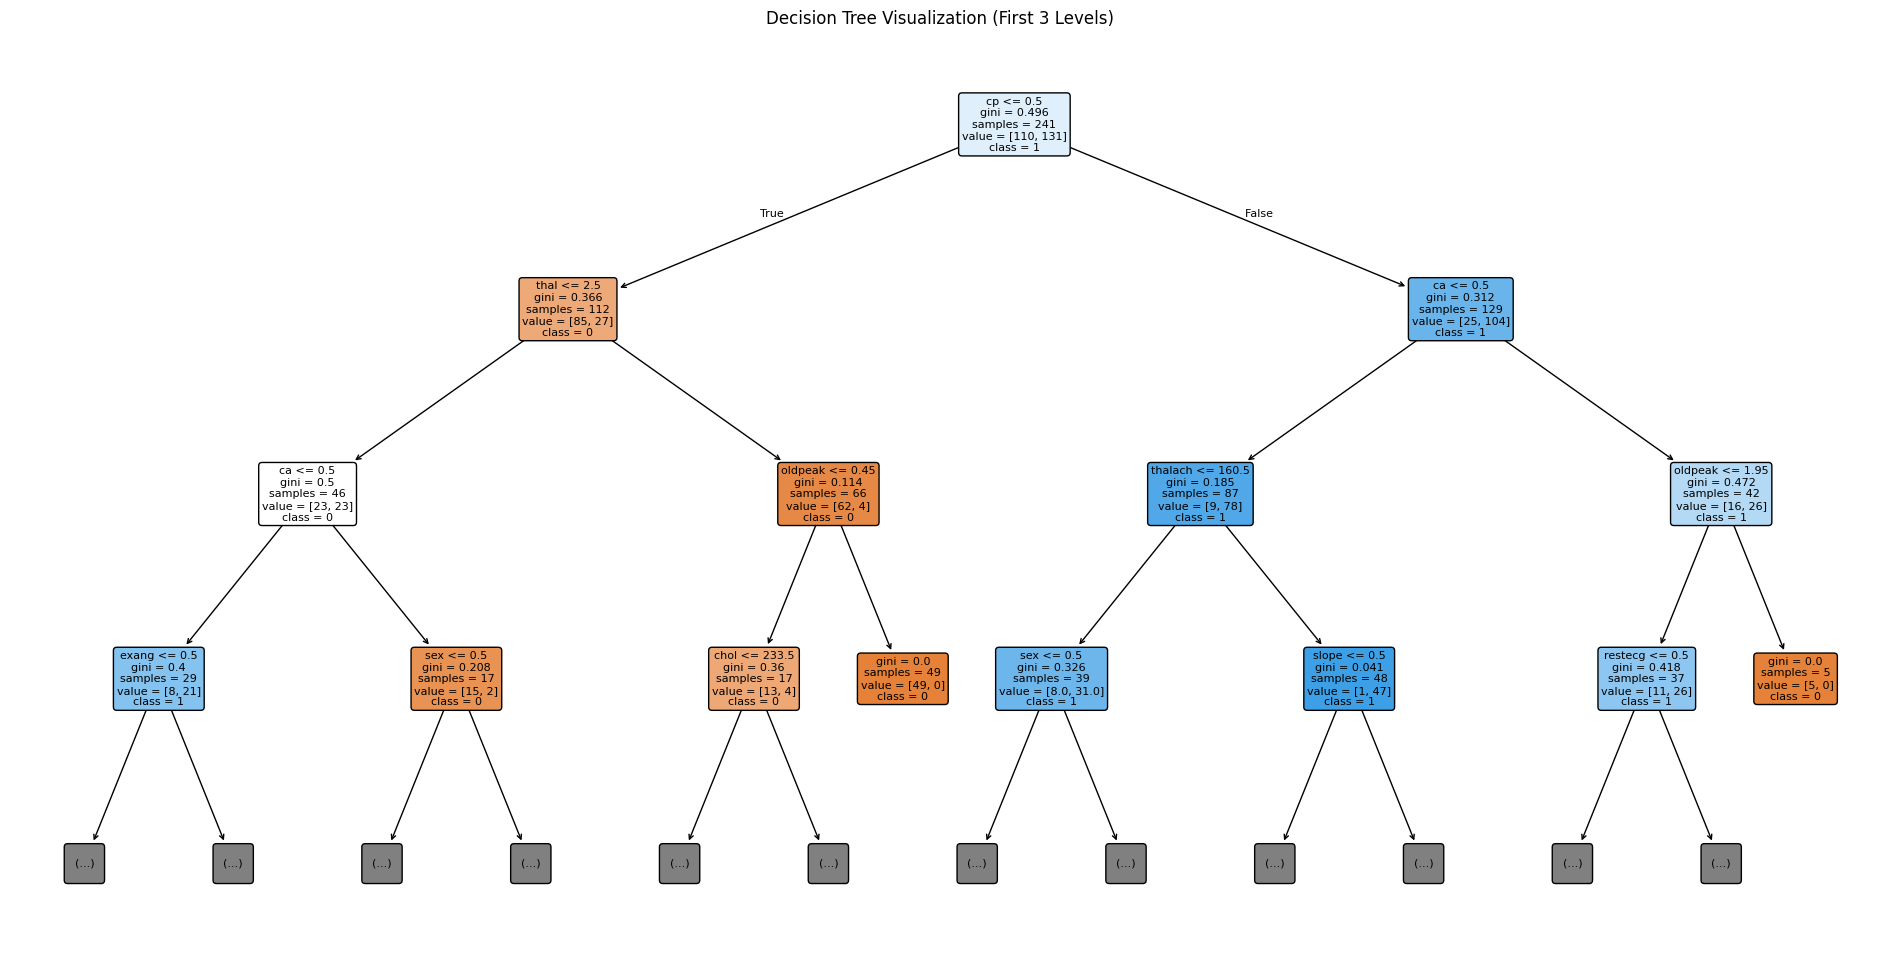

In [8]:
plt.figure(figsize=(24, 12))

plot_tree(
    decision_tree,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in decision_tree.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.show()

In [9]:
tree_rules = export_text(
    decision_tree,
    feature_names=list(X.columns),
    max_depth=3
)

print(tree_rules)

|--- cp <= 0.50
|   |--- thal <= 2.50
|   |   |--- ca <= 0.50
|   |   |   |--- exang <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- exang >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- ca >  0.50
|   |   |   |--- sex <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- sex >  0.50
|   |   |   |   |--- class: 0
|   |--- thal >  2.50
|   |   |--- oldpeak <= 0.45
|   |   |   |--- chol <= 233.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- chol >  233.50
|   |   |   |   |--- class: 0
|   |   |--- oldpeak >  0.45
|   |   |   |--- class: 0
|--- cp >  0.50
|   |--- ca <= 0.50
|   |   |--- thalach <= 160.50
|   |   |   |--- sex <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- sex >  0.50
|   |   |   |   |--- truncated branch of depth 6
|   |   |--- thalach >  160.50
|   |   |   |--- slope <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- slope >  0.50
|   |   |   |   |--- c

,Max Depth,Training Accuracy,Testing Accuracy
0,1,0.7842,0.6557
1,2,0.7842,0.6557
2,3,0.8589,0.8033
3,4,0.8714,0.7213
4,5,0.9419,0.7705
5,7,0.9793,0.7705
6,10,1.0000,0.8033
7,None,1.0000,0.8033


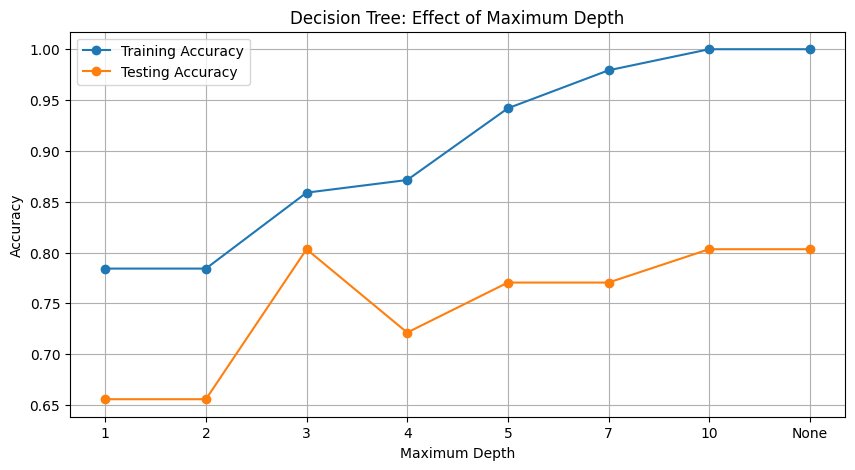

In [10]:
depth_results = []

for depth in [1, 2, 3, 4, 5, 7, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))

plt.figure(figsize=(10, 5))
plt.plot(
    depth_df["Max Depth"],
    depth_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    depth_df["Max Depth"],
    depth_df["Testing Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.title("Decision Tree: Effect of Maximum Depth")
plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    max_features="sqrt",
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

y_train_pred_rf = random_forest.predict(X_train)
y_test_pred_rf = random_forest.predict(X_test)

train_accuracy_rf = accuracy_score(y_train, y_train_pred_rf)
test_accuracy_rf = accuracy_score(y_test, y_test_pred_rf)

print("Random Forest Results")
print("-" * 35)
print(f"Training accuracy: {train_accuracy_rf:.4f}")
print(f"Testing accuracy:  {test_accuracy_rf:.4f}")

Random Forest Results
-----------------------------------
Training accuracy: 1.0000
Testing accuracy:  0.7541


,Model,Training Accuracy,Testing Accuracy
0,Decision Tree,1.0,0.8033
1,Random Forest,1.0,0.7541


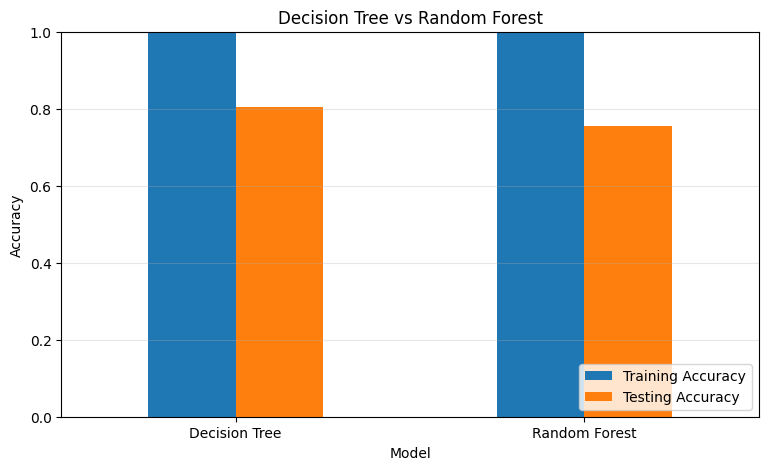

In [12]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [train_accuracy_dt, train_accuracy_rf],
    "Testing Accuracy": [test_accuracy_dt, test_accuracy_rf]
})

display(comparison.round(4))

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [13]:
print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred_dt,
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



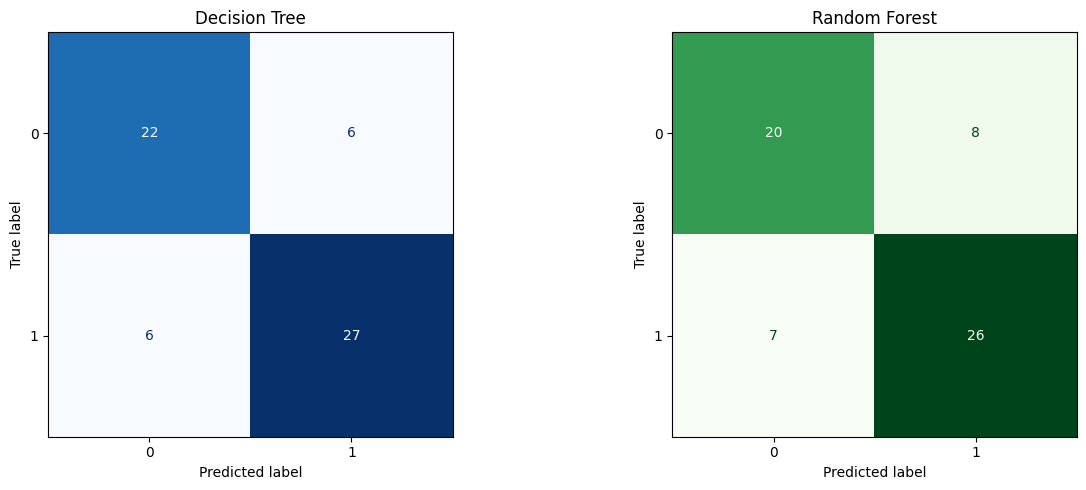

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_dt,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_rf,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

Top 10 Random Forest features:


,Decision Tree,Random Forest
cp,0.3314,0.1663
thalach,0.0280,0.1287
ca,0.1024,0.1094
thal,0.1015,0.0997
oldpeak,0.0798,0.0931
age,0.0367,0.0868
exang,0.0385,0.0728
chol,0.0961,0.0709
trestbps,0.0968,0.0701
sex,0.0330,0.0375


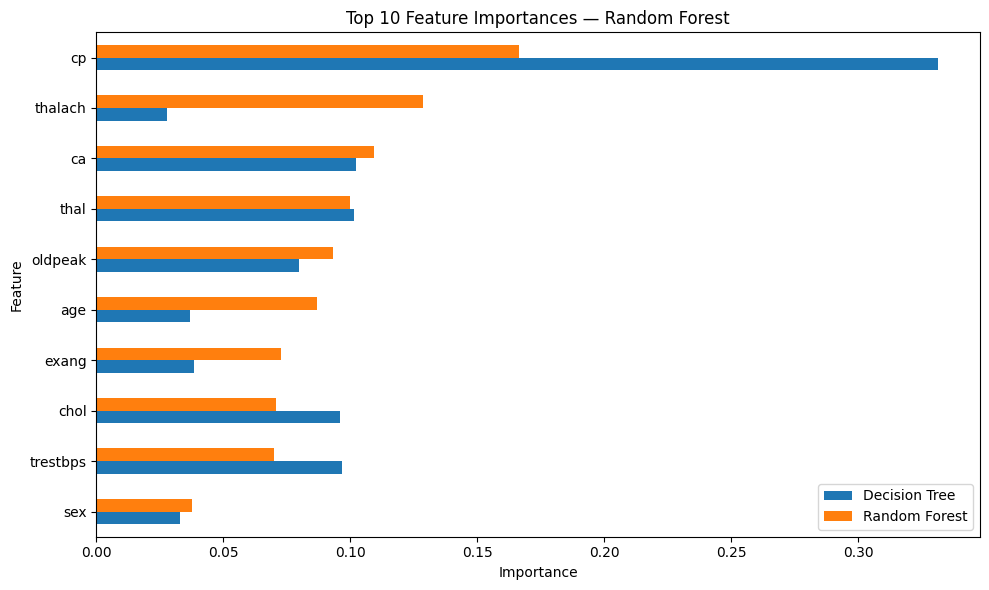

In [15]:
dt_importance = pd.Series(
    decision_tree.feature_importances_,
    index=X.columns,
    name="Decision Tree"
)

rf_importance = pd.Series(
    random_forest.feature_importances_,
    index=X.columns,
    name="Random Forest"
)

importance_df = pd.concat(
    [dt_importance, rf_importance],
    axis=1
).fillna(0)

print("Top 10 Random Forest features:")
display(
    importance_df.sort_values(
        "Random Forest",
        ascending=False
    ).head(10).round(4)
)

importance_df.sort_values(
    "Random Forest",
    ascending=True
).tail(10).plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [16]:
min_class_count = y_train.value_counts().min()
n_splits = min(5, int(min_class_count))

if n_splits < 2:
    print(
        "Not enough training samples per class for stratified "
        "cross-validation. More data is needed."
    )
else:
    cv = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    dt_cv_scores = cross_val_score(
        DecisionTreeClassifier(random_state=42),
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    rf_cv_scores = cross_val_score(
        RandomForestClassifier(
            n_estimators=200,
            max_features="sqrt",
            random_state=42,
            n_jobs=1
        ),
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    print("Decision Tree cross-validation scores:")
    print(np.round(dt_cv_scores, 4))
    print(f"Mean accuracy: {dt_cv_scores.mean():.4f}")
    print(f"Standard deviation: {dt_cv_scores.std():.4f}")

    print("\nRandom Forest cross-validation scores:")
    print(np.round(rf_cv_scores, 4))
    print(f"Mean accuracy: {rf_cv_scores.mean():.4f}")
    print(f"Standard deviation: {rf_cv_scores.std():.4f}")

Decision Tree cross-validation scores:
[0.7755 0.7708 0.75   0.8333 0.7708]
Mean accuracy: 0.7801
Standard deviation: 0.0280

Random Forest cross-validation scores:
[0.8571 0.8542 0.8125 0.9167 0.7917]
Mean accuracy: 0.8464
Standard deviation: 0.0430


In [17]:
final_results = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Training Accuracy": [
        train_accuracy_dt,
        train_accuracy_rf
    ],
    "Test Accuracy": [
        test_accuracy_dt,
        test_accuracy_rf
    ]
})

print("FINAL MODEL COMPARISON")
display(final_results.round(4))

best_model = (
    "Decision Tree"
    if test_accuracy_dt >= test_accuracy_rf
    else "Random Forest"
)

print(f"\nHigher test accuracy in this run: {best_model}")
print("\nRemember: compare cross-validation results too.")

FINAL MODEL COMPARISON


,Model,Training Accuracy,Test Accuracy
0,Decision Tree,1.0,0.8033
1,Random Forest,1.0,0.7541



Higher test accuracy in this run: Decision Tree

Remember: compare cross-validation results too.
